In [19]:
from tbparse import SummaryReader
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np

In [3]:
logdir = "runs"
reader = SummaryReader(logdir, extra_columns={"dir_name"})

In [13]:
data = reader.scalars
data.rename(columns={"dir_name": "run_name"}, inplace=True)
data["run_category"] = data["run_name"].str.split("_").str[:-2].str.join("_")
data["run_seed"] = data["run_name"].str.split("_").str[-1]
data["aux_weight"] = data["run_name"].str.split("_").str[-2].str[1:]
data.columns

Index(['step', 'tag', 'value', 'run_name', 'run_category', 'run_seed',
       'aux_weight'],
      dtype='object')

In [15]:
data["tag"].unique()

array(['aux/r2_score_angular_velocity_y',
       'aux/r2_score_track_curvature_0_50',
       'aux/r2_score_track_curvature_1_00',
       'aux/r2_score_track_curvature_1_50',
       'aux/r2_score_track_curvature_2_00',
       'aux/r2_score_track_curvature_2_50',
       'aux/r2_score_track_curvature_3_00',
       'aux/r2_score_track_curvature_3_50',
       'aux/r2_score_track_curvature_4_00',
       'aux/r2_score_track_curvature_4_50',
       'aux/r2_score_track_curvature_5_00',
       'aux/r2_score_track_curvature_5_50',
       'aux/r2_score_track_curvature_6_00',
       'aux/r2_score_track_curvature_6_50',
       'aux/r2_score_track_curvature_7_00',
       'aux/r2_score_track_curvature_7_50',
       'aux/r2_score_track_curvature_8_00',
       'aux/r2_score_velocity_forward', 'aux/r2_score_velocity_lateral',
       'aux/r2_score_wheel_slip_forward_back_left',
       'aux/r2_score_wheel_slip_forward_back_right',
       'aux/r2_score_wheel_slip_forward_front_left',
       'aux/r2_score_wh

In [23]:
def auc(g):
    return np.trapz(g["value"], g["step"])

completed_runs = data[data["step"] == 599]

rewards = data[(data["tag"] == "reward/mean")].sort_values("step")
# get only the ones that are finished
rewards = rewards[rewards.groupby("run_name")["step"].transform("max") >= 599]

auc_df = (
    rewards.groupby(["run_category", "aux_weight", "run_seed"])
           .apply(auc, include_groups=False)
           .rename("auc")
           .reset_index()
)
auc_df

,run_category,aux_weight,run_seed,auc
0,all,0.1,s0,72.570749
1,all,0.3,s0,67.416031
2,all,1,s0,36.652632
3,angular_velocity_y,0.1,s0,62.496294
4,angular_velocity_y,0.1,s1,81.658563
...,...,...,...,...
59,wheel_slip_rear_lateral,0.1,s1,86.369531
60,wheel_slip_rear_lateral,0.3,s0,40.137870
61,wheel_slip_rear_lateral,0.3,s1,82.225198
62,wheel_slip_rear_lateral,1,s0,77.952068


In [ ]:
auc_df \
    .groupby(["run_category", "aux_weight"])["auc"] \
    .agg(["mean", "std"]).reset_index().sort_values("mean")

sns

,run_category,aux_weight,mean,std
24,wheel_slip_front_forward,1,29.693723,38.980972
30,wheel_slip_rear_forward,1,30.979879,28.654171
2,all,1,36.652632,NaN
11,curvature_far,0.3,50.392231,4.261996
33,wheel_slip_rear_lateral,1,55.270918,32.075991
23,wheel_slip_front_forward,0.3,56.923891,2.969306
32,wheel_slip_rear_lateral,0.3,61.181534,29.760235
29,wheel_slip_rear_forward,0.3,62.873435,7.864308
1,all,0.3,67.416031,NaN
17,velocity_forward,0.3,68.538965,4.081453


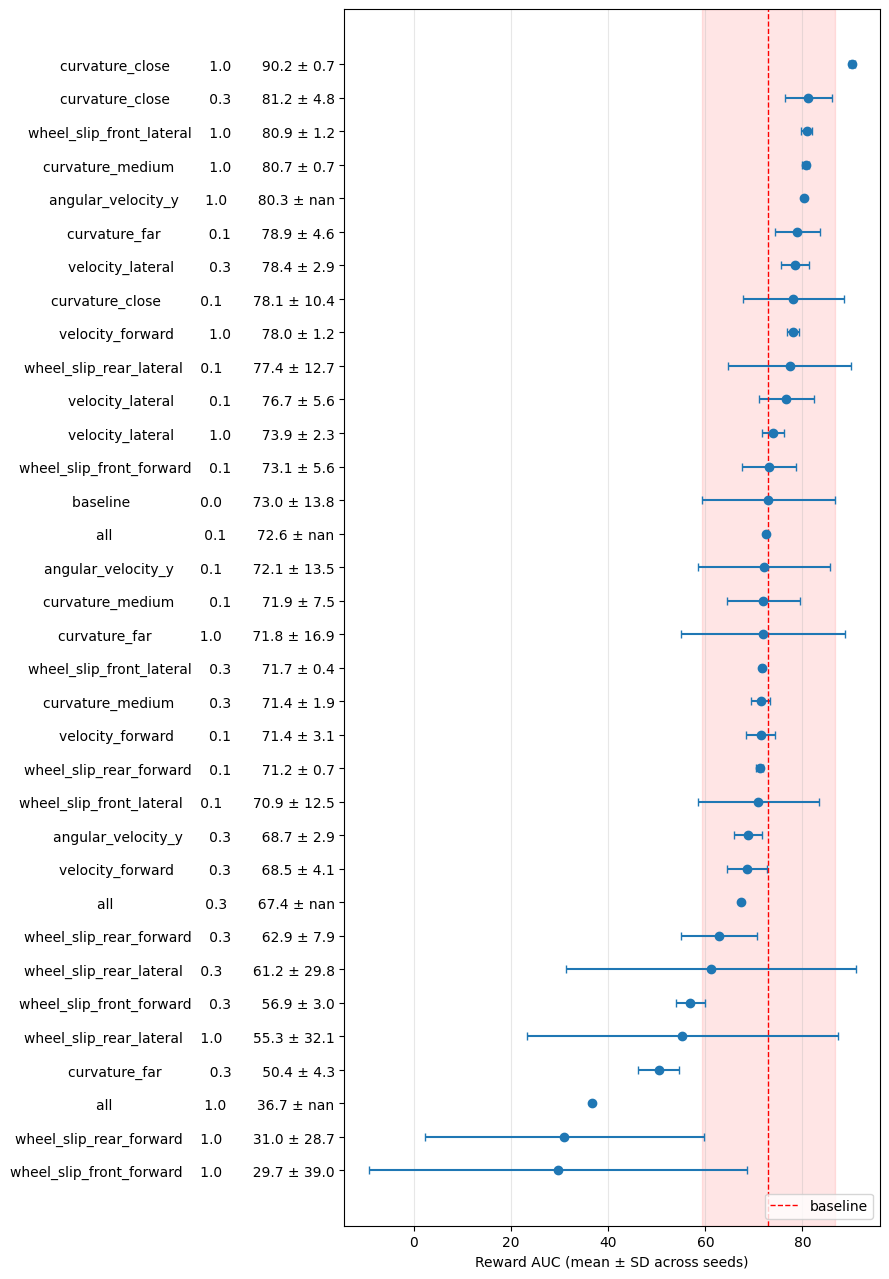

In [33]:
import matplotlib.pyplot as plt

summary = (
    auc_df.groupby(["run_category", "aux_weight"])["auc"]
          .agg(["mean", "std"])
          .reset_index()
          .sort_values("mean")
          .reset_index(drop=True)
)

labels = [
    f"{r.run_category:<20} {r.aux_weight:>6}   {r['mean']:8.1f} ± {r['std']:.1f}"
    for _, r in summary.iterrows()
]

fig, ax = plt.subplots(figsize=(9, 0.35 * len(summary) + 1))
ax.errorbar(summary["mean"], summary.index, xerr=summary["std"], fmt="o", capsize=3)

ax.set_yticks(summary.index, labels)
ax.set_xlabel("Reward AUC (mean ± SD across seeds)")
ax.grid(axis="x", alpha=0.3)

base = summary[summary["run_category"] == "baseline"].iloc[0]

ax.axvline(base["mean"], color="red", ls="--", lw=1, label="baseline")
ax.axvspan(base["mean"] - base["std"], base["mean"] + base["std"], color="red", alpha=0.1)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()